# Trajectoire eSAF dans le TYNDP 2026 : ce qu'elle implique en amont

**Master — séance de travail guidée.** Dans ce carnet nous suivons les carburants de synthèse (*e-fuels*, dont l'eSAF, kérosène de synthèse durable) dans les scénarios **TYNDP 2026** d'ENTSO-E / ENTSOG, puis nous calculons ce qu'il faut produire en amont (hydrogène, électricité, CO₂, eau) pour les fabriquer, et nous le confrontons à l'obligation européenne **ReFuelEU Aviation**.

Plan :
1. Charger les données et choisir un pays (variable en tête de carnet) ;
2. Les carburants de l'aviation par vecteur énergétique ;
3. Ce que TYNDP dit — et ne dit pas — des carburants de synthèse ;
4. De l'hydrogène des e-liquides au volume d'eSAF : une méthode explicite ;
5. Trajectoire eSAF contre l'obligation ReFuelEU ;
6. Besoins amont (H₂, électricité, CO₂, eau) avec fourchettes sourcées et sensibilité ;
7. Comparaison des scénarios NT+, HEV, LEV : UE-27 contre le pays choisi ;
8. **Exercices ouverts**.

> Convention : toutes les énergies sont en **TWh** sur le pouvoir calorifique inférieur (PCI). « TWh H₂ » = énergie de l'hydrogène consommé (PCI), pas celle du carburant produit.
> Tout ce qui est imprimé vient soit des données, soit d'un facteur cité avec sa source. Ce qui n'a pas pu être vérifié est marqué **[À VÉRIFIER]**.

## 0. Mise en place

La cellule ci-dessous importe les bibliothèques et **cherche le dossier `data/`**.
- En local (Jupyter), le dossier `data/` est à côté de `notebooks/` : rien à faire.
- Sur Google Colab, le dépôt est **privé** : soit vous collez un jeton d'accès personnel GitHub (lecture) pour cloner, soit vous laissez vide et vous téléversez les 5 CSV du dossier `data/` à la main.

In [1]:
import sys, os, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OWNER, REPO = "Silake-prog", "students-usaf"
FICHIERS = ["aviation_fuel_by_carrier.csv", "liquids_all_sectors.csv", "tyndp_efuels_kpi.csv",
            "countries.csv", "refueleu_annex1.csv"]

def trouver_data():
    """Renvoie le dossier data/ s'il existe à un endroit attendu, sinon None."""
    for c in [Path("data"), Path("../data"), Path(REPO) / "data"]:
        if all((c / f).exists() for f in FICHIERS):
            return c
    return None

DATA = trouver_data()
if DATA is None and "google.colab" in sys.modules:
    from getpass import getpass
    jeton = getpass("Jeton GitHub (lecture du dépôt privé) — laisser vide pour téléverser à la main : ").strip()
    if jeton:
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        subprocess.run(["git", "clone", "--depth", "1", f"https://{jeton}@github.com/{OWNER}/{REPO}.git"], env=env)
        DATA = trouver_data()
    if DATA is None:
        from google.colab import files
        os.makedirs("data", exist_ok=True)
        print("Téléversez les fichiers du dossier data/ :", FICHIERS)
        for nom, contenu in files.upload().items():
            open(Path("data") / nom, "wb").write(contenu)
        DATA = trouver_data()
assert DATA is not None, "Dossier data/ introuvable : lancez le carnet depuis notebooks/ ou suivez les instructions ci-dessus."
print("Données lues dans :", DATA.resolve())

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

Données lues dans : /Users/simonbrigode/paper_projects/tyndp-esaf-students/data


### Paramètres à modifier

- `PAYS` : code TYNDP à deux lettres du pays étudié (`FR`, `DE`, `ES`, `IT`, `NL`… voir `data/countries.csv`). Le Grec est `GR`.
- `SCENARIO_REF` : scénario de référence (`NT+` = National Trends+, le seul publié pour 2030 et 2050 ; `HEV` et `LEV` = variantes économiques haute et basse, **publiées seulement pour 2035 et 2040**).

In [2]:
PAYS = "FR"            # <- à changer
SCENARIO_REF = "NT+"
ANNEES = [2030, 2035, 2040, 2050]

## 1. Charger les données

Cinq petits fichiers (voir `data/README.md` pour les colonnes, unités et la provenance exacte de chaque ligne). **`pandas.read_csv`** lit un CSV dans un `DataFrame` (tableau). Nous regardons toujours la forme (`shape`), les premières lignes (`head`) et les valeurs distinctes des colonnes clés avant de calculer quoi que ce soit.

In [3]:
av   = pd.read_csv(DATA / "aviation_fuel_by_carrier.csv")   # aviation : énergie finale par vecteur
liq  = pd.read_csv(DATA / "liquids_all_sectors.csv")        # tous les secteurs : vecteur « Liquids » seul
kpi  = pd.read_csv(DATA / "tyndp_efuels_kpi.csv")           # lignes e-fuels du tableau de bord KPI
pays = pd.read_csv(DATA / "countries.csv")
ref  = pd.read_csv(DATA / "refueleu_annex1.csv")            # Règlement (UE) 2023/2405, annexe I

UE27 = pays.loc[pays.ue27 == "oui", "code"].tolist()
assert PAYS in UE27, f"{PAYS} n'est pas dans l'UE-27 (liste : {UE27})"
print(len(UE27), "pays dans l'UE-27 ; la Suisse (CH) est exclue de l'agrégat.")
for nom, d in [("av", av), ("liq", liq), ("kpi", kpi)]:
    print(f"{nom:4s} {d.shape}")
av.head()

27 pays dans l'UE-27 ; la Suisse (CH) est exclue de l'agrégat.
av   (1344, 6)
liq  (8064, 8)
kpi  (1507, 10)


,variant,country,year,subsector,carrier,twh
0,HEV,AT,2035,International aviation,Electricity,0.000000
1,HEV,AT,2035,International aviation,Hydrogen,0.000000
2,HEV,AT,2035,International aviation,Liquids,7.887876
3,HEV,AT,2035,Planes,Electricity,0.000000
4,HEV,AT,2035,Planes,Hydrogen,0.000000


In [4]:
# Valeurs distinctes : que contient chaque colonne ?
print("scénarios     :", sorted(av.variant.unique()))
print("années        :", sorted(av.year.unique()))
print("sous-secteurs :", sorted(av.subsector.unique()))
print("vecteurs      :", sorted(av.carrier.unique()))
print("\nAnnées publiées par scénario :")
print(av.groupby("variant").year.unique().apply(sorted))

scénarios     : ['HEV', 'LEV', 'NT+']
années        : [np.int64(2030), np.int64(2035), np.int64(2040), np.int64(2050)]
sous-secteurs : ['International aviation', 'Planes']
vecteurs      : ['Electricity', 'Hydrogen', 'Liquids']

Années publiées par scénario :
variant
HEV                [2035, 2040]
LEV                [2035, 2040]
NT+    [2030, 2035, 2040, 2050]
Name: year, dtype: object


## 2. Les carburants de l'aviation, par vecteur

TYNDP (via l'*Energy Transition Model*) distingue deux sous-secteurs :
- **International aviation** : vols internationaux (soutes) ;
- **Planes** : aviation « domestique » rangée dans les transports.

Pour l'UE-27 nous **additionnons les 27 pays** (`groupby` puis `sum`). Le piège classique : oublier d'exclure la Suisse (`CH`) ou de filtrer l'année avant de sommer.

In [5]:
def ue27(df, cols_groupe):
    """Somme des 27 pays de l'UE : filtre les pays, puis agrège sur les colonnes demandées (twh en TWh)."""
    return df[df.country.isin(UE27)].groupby(cols_groupe, as_index=False).twh.sum()

av_ue = ue27(av, ["variant", "year", "subsector", "carrier"])
t = (av_ue[av_ue.variant == SCENARIO_REF]
     .pivot_table(index=["subsector", "carrier"], columns="year", values="twh").round(1))
print(f"Énergie finale de l'aviation, UE-27, scénario {SCENARIO_REF} (TWh)")
t

Énergie finale de l'aviation, UE-27, scénario NT+ (TWh)


year                                 2030   2035   2040   2050
subsector              carrier                                
International aviation Electricity    0.0    0.0    0.0    1.2
                       Hydrogen       0.3    0.7    3.5   10.7
                       Liquids      519.4  503.1  520.2  501.3
Planes                 Electricity    0.1    0.6    1.1    2.0
                       Hydrogen       0.2    0.5    0.9    1.7
                       Liquids       84.5   80.2   70.9   65.1

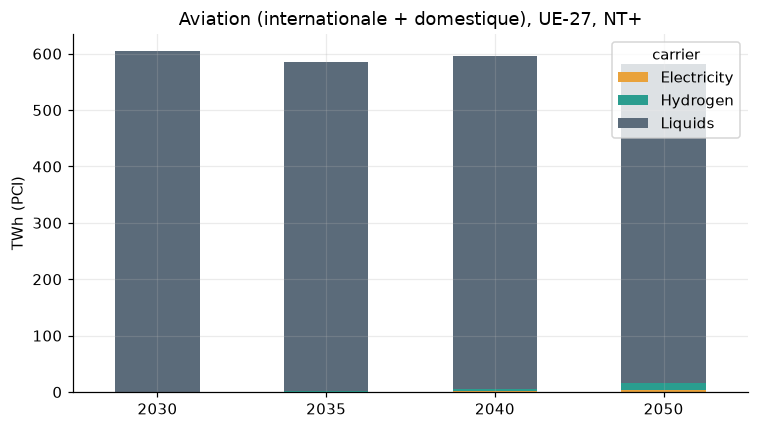

carrier  Electricity  Hydrogen  Liquids
year                                   
2030             0.0       0.1     99.9
2035             0.1       0.2     99.7
2040             0.2       0.7     99.1
2050             0.6       2.1     97.3


In [6]:
# Figure 1 : aviation UE-27 par vecteur, scénario de référence
fig, ax = plt.subplots(figsize=(7, 4))
x = av_ue[av_ue.variant == SCENARIO_REF].groupby(["year", "carrier"]).twh.sum().unstack("carrier")
x.plot.bar(stacked=True, ax=ax, color={"Liquids": "#5b6b7a", "Hydrogen": "#2a9d8f", "Electricity": "#e9a23b"}, rot=0)
ax.set_ylabel("TWh (PCI)"); ax.set_xlabel("")
ax.set_title(f"Aviation (internationale + domestique), UE-27, {SCENARIO_REF}")
plt.tight_layout(); plt.show()
print((x.div(x.sum(axis=1), axis=0) * 100).round(1))

**Lecture.** Le vecteur `Liquids` fait plus de 95 % de l'énergie de l'aviation à tous les horizons, y compris 2050 (les parts d'hydrogène et d'électricité sont inférieures à quelques pour cent d'après le tableau ci-dessus). La demande d'énergie de l'aviation reste à peu près stable (de l'ordre de 600 TWh) alors que les liquides de l'ensemble de l'économie baissent fortement (voir section 4). Que contient ce « Liquids » ? C'est l'objet de la section suivante.

## 3. Ce que TYNDP dit — et ne dit pas — des carburants de synthèse

**Constat** : le tableau de demande finale d'ETM n'a **aucune ligne « kérosène fossile / biokérosène / e-kérosène »**. Dans l'aviation il n'y a qu'un vecteur `Liquids` (l'identifiant d'origine est `..._final_demand_oil`), plus `Hydrogen`, `Electricity`, et des vecteurs nuls (biomasse, méthane, ammoniac…). Vérifions-le sur les données.

In [7]:
print("Vecteurs non nuls dans l'aviation (fichier livré) :", sorted(av.carrier.unique()))
print("Y a-t-il une colonne qui sépare fossile / bio / synthétique ?  Colonnes :", list(av.columns))

Vecteurs non nuls dans l'aviation (fichier livré) : ['Electricity', 'Hydrogen', 'Liquids']
Y a-t-il une colonne qui sépare fossile / bio / synthétique ?  Colonnes : ['variant', 'country', 'year', 'subsector', 'carrier', 'twh']


La synthèse apparaît **ailleurs**, dans le tableau de bord KPI (partie hydrogène du TYNDP), à l'échelle de **tous les usages ensemble** : kérosène, diesel maritime, naphta, etc. Voici les lignes retenues.

In [8]:
cles = ["section", "block", "label", "unit"]
print(kpi[kpi.country == "EU27"].groupby(cles).size().to_string())
print("\nValeurs textuelles (non numériques) dans les lignes pays :")
print(kpi[kpi.note.notna()].groupby(["label", "note"]).size().to_string())

section             block    label                         unit  
Consumption         CO2      CO2 to E-Fuels [kt]           kt        8
                    E-Fuels  E-Fuel Demand [TWh H2]        TWh H2    4
                             E-Fuel Shortage [TWh H2]      TWh H2    4
                    Fuels    E-Fuel Demand [TWh H2]        TWh H2    4
                             E-Fuel Shortage [TWh H2]      TWh H2    4
                    H2       H2 to E-Liquids               TWh H2    8
                             H2 to SNG                     TWh H2    8
Energy Balance      H2 -     H2 to eFuels                  TWh H2    8
Exchange            E-Fuels  E-Liquid Imports [TWh H2]     TWh H2    8
                             SNG Imports [TWh H2]          TWh H2    8
FLH                 H2       H2 to E-Liquids               h         8
                             H2 to SNG                     h         8
Installed Capacity  H2       E-Liquids Capacity (from H2)  GW        8
           

- `H2 to E-Liquids` et `H2 to SNG` : hydrogène consommé par les usines de e-liquides et de méthane de synthèse, en **TWh d'H₂**. Disponible **par pays** là où l'on produit (seulement quelques pays, voir section 8) et pour l'**UE-27**.
- `E-Liquid Imports` / `SNG Imports` : importations de e-fuels, exprimées en **TWh d'H₂ équivalent**, **uniquement à l'échelle UE-27** (pour les pays, la case contient le texte `EU27 level specific`).
- `E-Fuel Demand [TWh H2]` : demande totale de e-fuels de l'UE-27, **identique dans les trois scénarios** (c'est une entrée du scénario, pas un résultat).
- `CO2 to E-Fuels [kt]` : CO₂ utilisé. Le libellé dit « kt » mais l'ordre de grandeur (80 en 2050 pour près de 1 000 TWh H₂ de e-fuels) n'a de sens qu'en **Mt** : **[À VÉRIFIER]** auprès d'ENTSO-E.

Nous contrôlons d'abord la **cohérence comptable** : la demande de e-fuels doit être couverte par production européenne + importations.

In [9]:
k = kpi[(kpi.country == "EU27") & (kpi.variant == SCENARIO_REF) & (kpi.section.isin(["Consumption", "Exchange"]))]
p = k.pivot_table(index="label", columns="year", values="value")
bilan = pd.DataFrame({
    "H2 vers e-liquides (prod. UE)": p.loc["H2 to E-Liquids"],
    "Imports e-liquides":            p.loc["E-Liquid Imports [TWh H2]"],
    "H2 vers SNG (prod. UE)":        p.loc["H2 to SNG"],
    "Imports SNG":                   p.loc["SNG Imports [TWh H2]"],
})
bilan["Somme"] = bilan.sum(axis=1)
bilan["Demande e-fuels (entrée)"] = p.loc["E-Fuel Demand [TWh H2]"]
bilan["Écart"] = bilan["Somme"] - bilan["Demande e-fuels (entrée)"]
print(f"Bilan e-fuels UE-27, {SCENARIO_REF}, TWh H2")
print(bilan.round(1).T.to_string())
assert bilan["Écart"].abs().max() < 0.5, "Le bilan ne boucle pas !"

Bilan e-fuels UE-27, NT+, TWh H2
year                            2030   2035   2040   2050
H2 vers e-liquides (prod. UE)   43.5  122.9  187.7  410.9
Imports e-liquides              64.4  149.2  279.5  481.7
H2 vers SNG (prod. UE)           2.0    8.2    9.0   23.3
Imports SNG                      2.4   13.0   29.1   60.6
Somme                          112.4  293.3  505.3  976.4
Demande e-fuels (entrée)       112.4  293.3  505.3  976.4
Écart                           -0.0   -0.0    0.0    0.0


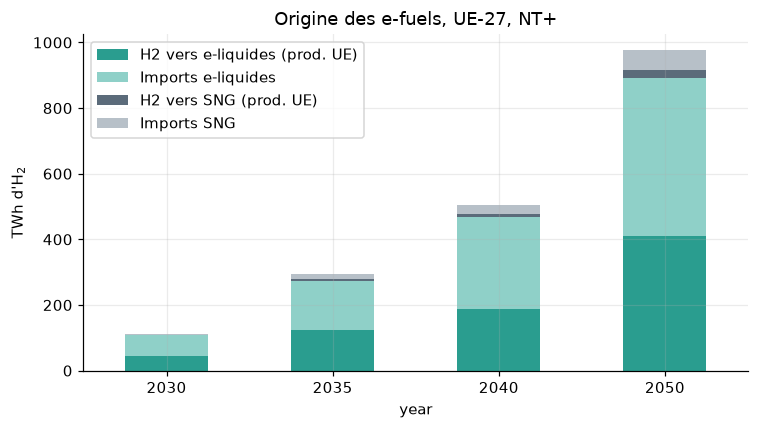

Part importée des e-liquides : {2030: 60.0, 2035: 55.0, 2040: 60.0, 2050: 54.0} %


In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
bilan.iloc[:, :4].plot.bar(stacked=True, ax=ax, rot=0, color=["#2a9d8f", "#8fd0c8", "#5b6b7a", "#b7c0c8"])
ax.set_ylabel("TWh d'H$_2$"); ax.set_title(f"Origine des e-fuels, UE-27, {SCENARIO_REF}")
plt.tight_layout(); plt.show()
print("Part importée des e-liquides :", (bilan["Imports e-liquides"] / (bilan["Imports e-liquides"] + bilan["H2 vers e-liquides (prod. UE)"]) * 100).round(0).to_dict(), "%")

**Lecture.** Le bilan boucle (écart nul à l'arrondi près). Plus de la moitié des e-liquides (54 à 60 % selon l'année) est **importée** à tous les horizons dans NT+ : une trajectoire « eSAF européen » dépend donc beaucoup des imports hors UE-27. Notez aussi le point méthodologique : cette demande de e-fuels est une **entrée** du scénario ; la ligne `H2 to E-Liquids` est le **résultat** de l'optimisation (part produite en Europe).

## 4. De l'hydrogène des e-liquides au volume d'eSAF : la méthode

TYNDP ne sépare pas l'eSAF. Nous le **dérivons** en trois étapes, toutes explicites :

1. **Volume de e-liquides** (TWh de carburant) = (`H2 to E-Liquids` + `E-Liquid Imports`) × **η_H₂→liquide**, le rendement de la synthèse Fischer–Tropsch (FT) ramené à l'énergie de l'hydrogène.
2. **Part de e-liquides** dans les liquides de l'UE-27 = volume de e-liquides ÷ demande totale de `Liquids` de tous les secteurs (tableau `liquids_all_sectors.csv`).
3. **Deux hypothèses d'affectation à l'aviation** :
   - **au prorata** (borne basse) : l'aviation reçoit la même part de e-liquides que les autres usages ;
   - **aviation d'abord** (borne haute) : tous les e-liquides vont d'abord à l'aviation, dans la limite de son besoin en liquides.

   La réalité est entre les deux. L'obligation ReFuelEU est précisément ce qui pousserait vers « aviation d'abord ».

### Les facteurs de rendement et leurs sources

| Paramètre | Bas | Central | Haut | Source |
|---|---|---|---|---|
| η_H₂→liquide (FT, par rapport à l'H₂) | 0,56 | 0,68 | 0,70 | Bas et central : **dérivés** de Concawe (2024) : rendement électricité→e-kérosène FT en 2050 **42 %** (CO₂ capté dans l'air) ou **51 %** (CO₂ concentré), divisé par le rendement d'électrolyse **75 %** (électrolyseur alcalin 2050), soit 0,56 et 0,68. Haut : **implicite** dans TYNDP lui-même (section 6) |
| η_électricité→carburant (FT) | 0,42 | 0,51 | 0,60 | Bas et central : Concawe (2024), idem. Haut : Ueckerdt et al. (2021) *Nature Climate Change* : « pertes d'environ 40 % » de l'électricité au carburant |
| η électrolyse (PCI) | 0,665 (2020) | 0,68 (2030) | 0,75 (2050) | Concawe (2024), tableau 1 (valeurs de l'AIE) |
| CO₂ dans le kérosène | 73,6 g CO₂/MJ | | | Concawe (2024) : « CO₂ lié dans le carburant final » FTK/FTD (73,6 / 73,2 g/MJ) ; contrôlé plus bas par la stœchiométrie |
| Eau | 9 kg d'eau par kg d'H₂ | | | **Stœchiométrie** de l'électrolyse (2 H₂O → 2 H₂ + O₂) : un plancher, pas une valeur d'usine **[À VÉRIFIER]** |

Concawe (2024) : *E-Fuels: A techno-economic assessment of European domestic production and imports towards 2050 — Update*, Concawe Report 4/24. Ueckerdt et al. (2021), *Potential and risks of hydrogen-based e-fuels in climate change mitigation*, Nature Climate Change 11, 384–393.

> **Limite honnête** : le rendement « électricité → carburant » de Concawe inclut la capture du CO₂ (DAC) pour 42 % ; la valeur 51 % vaut pour un CO₂ concentré (industrie). Le rapport au rendement d'électrolyse n'isole donc pas exactement la seule étape de synthèse : c'est une **approximation** assumée et testée en sensibilité.

In [11]:
# Facteurs de rendement (cf. tableau ci-dessus). Chaque jeu est cohérent : « efficace » = besoins les plus faibles.
FACT = pd.DataFrame({
    "eta_h2_liq":    {"peu efficace": 0.42/0.75, "central": 0.51/0.75, "efficace": 0.70},
    "eta_elec_fuel": {"peu efficace": 0.42,      "central": 0.51,      "efficace": 0.60},
}).round(3)
print(FACT)
ETA = FACT.loc["central", "eta_h2_liq"]

              eta_h2_liq  eta_elec_fuel
peu efficace        0.56           0.42
central             0.68           0.51
efficace            0.70           0.60


In [12]:
# Étape 1 : volume de e-liquides de l'UE-27 (TWh de carburant), scénario de référence
def kpi_ue(label, section=None, variant=SCENARIO_REF):
    k = kpi[(kpi.country == "EU27") & (kpi.variant == variant) & (kpi.label == label)]
    if section: k = k[k.section == section]
    return k.set_index("year").value

def eliquides(variant, eta):
    h2 = kpi_ue("H2 to E-Liquids", "Consumption", variant) + kpi_ue("E-Liquid Imports [TWh H2]", variant=variant)
    return h2 * eta                      # TWh de carburant

# Étape 2 : demande de liquides tous secteurs et aviation
liq_tot = ue27(liq, ["variant", "year"]).set_index(["variant", "year"]).twh
liq_av  = (av_ue[av_ue.carrier == "Liquids"].groupby(["variant", "year"]).twh.sum())

def trajectoire(variant, eta):
    e = eliquides(variant, eta).dropna()
    idx = [(variant, y) for y in e.index]
    out = pd.DataFrame({"e_liquides": e.values,
                        "liquides_tous_secteurs": liq_tot.reindex(idx).values,
                        "aviation_liquides": liq_av.reindex(idx).values}, index=e.index)
    out["part_e_dans_liquides_%"] = 100 * out.e_liquides / out.liquides_tous_secteurs
    out["eSAF_prorata"] = out.aviation_liquides * out.e_liquides / out.liquides_tous_secteurs
    out["eSAF_aviation_d_abord"] = np.minimum(out.e_liquides, out.aviation_liquides)
    out["part_eSAF_prorata_%"] = 100 * out.eSAF_prorata / out.aviation_liquides
    out["part_eSAF_aviation_d_abord_%"] = 100 * out.eSAF_aviation_d_abord / out.aviation_liquides
    return out

T = trajectoire(SCENARIO_REF, ETA)
print(f"Trajectoire UE-27, {SCENARIO_REF}, η H2→liquide = {ETA}")
T.round(1).T

Trajectoire UE-27, NT+, η H2→liquide = 0.68


year,2030,2035,2040,2050
e_liquides,73.4,185.0,317.7,607.0
liquides_tous_secteurs,4840.3,3995.6,3226.2,1964.4
aviation_liquides,603.9,583.4,591.1,566.4
part_e_dans_liquides_%,1.5,4.6,9.8,30.9
eSAF_prorata,9.2,27.0,58.2,175.0
eSAF_aviation_d_abord,73.4,185.0,317.7,566.4
part_eSAF_prorata_%,1.5,4.6,9.8,30.9
part_eSAF_aviation_d_abord_%,12.2,31.7,53.8,100.0


**Lecture.** En 2050, les e-liquides pèseraient une part importante des liquides restants de l'UE-27 (colonne `part_e_dans_liquides_%`), alors que le volume de liquides total a fortement chuté. En « aviation d'abord » les e-liquides couvrent 12 % du besoin de l'aviation en 2030, 32 % en 2035, 54 % en 2040 et **100 % en 2050** (le volume de e-liquides, 607 TWh, y dépasse même les 566 TWh de liquides de l'aviation). L'écart entre les deux bornes mesure à lui seul l'importance de la règle d'affectation : c'est un **choix de modélisation**, pas une donnée.

## 5. Trajectoire eSAF contre l'obligation ReFuelEU

**Règlement (UE) 2023/2405 (ReFuelEU Aviation), annexe I** (texte lu sur EUR-Lex, version publiée au JO du 31.10.2023) : parts minimales de SAF et, en son sein, de carburants d'aviation **synthétiques**. Pour 2030-2031 la sous-obligation est une **moyenne** de 1,2 % (minimum annuel 0,7 %) ; pour 2032-2034 une moyenne de 2,0 % (minimum 1,2 % puis 2,0 %). L'obligation pèse sur les fournisseurs de carburant aux **aéroports de l'Union** ; le règlement raisonne sur le contenu énergétique pour l'hydrogène (art. 4) — nous l'appliquons à l'énergie : **[À VÉRIFIER]** la base exacte (énergie ou volume) pour les carburants liquides.

In [13]:
ref

,annee,part_saf_min_pct,part_synthetique_min_pct,remarque
0,2025,2,NaN,Annexe I (a) : 2 % de SAF chaque année à parti...
1,2030,6,1.2,Annexe I (b) : 6 % de SAF ; synthétique : MOYE...
2,2032,6,2.0,Annexe I (b)(ii) : synthétique : MOYENNE de 2....
3,2035,20,5.0,Annexe I (c)
4,2040,34,10.0,Annexe I (d)
5,2045,42,15.0,Annexe I (e)
6,2050,70,35.0,Annexe I (f)


In [14]:
# Obligation ReFuelEU rapportée au besoin en liquides de l'aviation de l'UE-27 (TWh)
mand = ref.set_index("annee")
yrs = [y for y in T.index if y in mand.index]
T["mandat_synth_%"] = [mand.loc[y, "part_synthetique_min_pct"] for y in T.index]
T["mandat_synth_TWh"] = T["mandat_synth_%"] / 100 * T.aviation_liquides
T["mandat_SAF_%"] = [mand.loc[y, "part_saf_min_pct"] for y in T.index]
print(T[["aviation_liquides", "mandat_synth_%", "mandat_synth_TWh", "eSAF_prorata", "eSAF_aviation_d_abord"]].round(1).to_string())

      aviation_liquides  mandat_synth_%  mandat_synth_TWh  eSAF_prorata  eSAF_aviation_d_abord
year                                                                                          
2030              603.9             1.2               7.2           9.2                   73.4
2035              583.4             5.0              29.2          27.0                  185.0
2040              591.1            10.0              59.1          58.2                  317.7
2050              566.4            35.0             198.2         175.0                  566.4


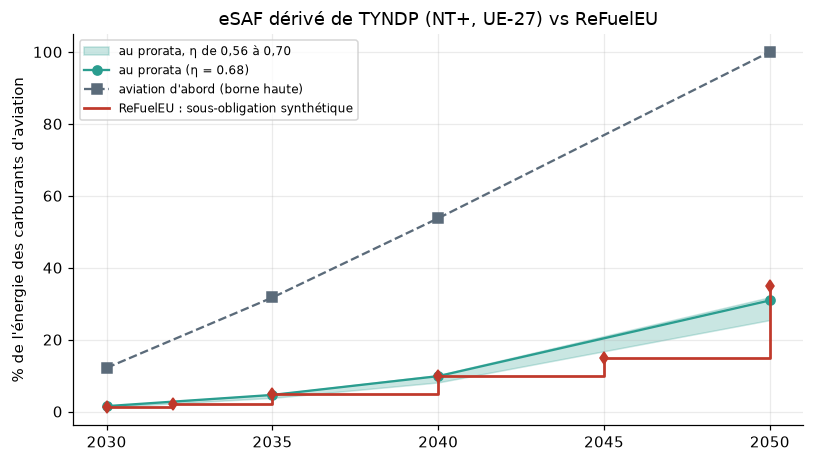

      prorata bas  prorata central  prorata haut  aviation d'abord  mandat
year                                                                      
2030          1.2              1.5           1.6              12.2     1.2
2035          3.8              4.6           4.8              31.7     5.0
2040          8.1              9.8          10.1              53.8    10.0
2050         25.4             30.9          31.8             100.0    35.0


In [15]:
# Figure 2 : part d'eSAF dans les carburants de l'aviation (UE-27) vs sous-obligation synthétique
fig, ax = plt.subplots(figsize=(7.5, 4.3))
bas  = trajectoire(SCENARIO_REF, FACT.loc["peu efficace", "eta_h2_liq"])["part_eSAF_prorata_%"]
haut = trajectoire(SCENARIO_REF, FACT.loc["efficace", "eta_h2_liq"])["part_eSAF_prorata_%"]
ax.fill_between(T.index, bas, haut, color="#2a9d8f", alpha=0.25, label="au prorata, η de 0,56 à 0,70")
ax.plot(T.index, T["part_eSAF_prorata_%"], "o-", color="#2a9d8f", label=f"au prorata (η = {ETA})")
ax.plot(T.index, T["part_eSAF_aviation_d_abord_%"], "s--", color="#5b6b7a", label="aviation d'abord (borne haute)")
ax.step(ref.annee[ref.annee >= 2030], ref.part_synthetique_min_pct[ref.annee >= 2030], where="post", color="#c0392b", lw=1.8,
        label="ReFuelEU : sous-obligation synthétique")
ax.plot(ref.annee[ref.annee >= 2030], ref.part_synthetique_min_pct[ref.annee >= 2030], "d", color="#c0392b")
ax.set_ylabel("% de l'énergie des carburants d'aviation"); ax.set_xticks([2030, 2035, 2040, 2045, 2050])
ax.set_title(f"eSAF dérivé de TYNDP ({SCENARIO_REF}, UE-27) vs ReFuelEU"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"prorata bas": bas, "prorata central": T["part_eSAF_prorata_%"], "prorata haut": haut,
                    "aviation d'abord": T["part_eSAF_aviation_d_abord_%"], "mandat": T["mandat_synth_%"]}).round(1))

**Lecture de la figure (à comparer aux nombres imprimés juste dessous).** Au prorata, la part d'eSAF suit de près l'obligation en 2030-2040 (1,5 % contre 1,2 %, 4,6 % contre 5 %, 9,8 % contre 10 %) puis reste **sous les 35 %** de 2050 pour les trois rendements (25 à 32 %) ; la borne « aviation d'abord » dépasse l'obligation à tous les horizons, ce qui signifie que **TYNDP contient assez de e-liquides pour la satisfaire**, à condition de les réserver à l'aviation. Les segments entre deux années TYNDP (par exemple 2040 à 2050) sont de simples droites : **TYNDP ne publie pas 2045**, il ne faut pas lire de valeur intermédiaire sur ces segments. Rappelons que l'obligation 2030 est une **moyenne 2030-2031**, tracée ici à la valeur 1,2 % ; en 2050 la barre ne comprend pas le reste du SAF (70 % au total, dont 35 % de synthétique).

## 6. Besoins amont pour produire l'eSAF

Pour un volume d'eSAF donné (TWh de carburant) :

- **Hydrogène** = eSAF ÷ η_H₂→liquide ;
- **Électricité** = eSAF ÷ η_électricité→carburant (tout compris : électrolyse, capture de CO₂, synthèse) ;
- **CO₂** = eSAF × 73,6 g/MJ, soit 265 kt/TWh (Concawe 2024) ;
- **Eau** (plancher stœchiométrique) = H₂ × 9 kg/kg d'H₂ ÷ 33,3 kWh/kg (PCI de l'H₂).

Nous contrôlons d'abord le CO₂ par la stœchiométrie : un hydrocarbure moyen de formule CH₂ (PCI ≈ 43,2 MJ/kg pour le kérosène).

In [16]:
# Contrôle stœchiométrique du CO2 par MJ de kérosène (CH2 ≈ unité répétée de la chaîne)
M_CO2, M_CH2 = 44.0, 14.0           # g/mol
PCI_KERO = 43.2                      # MJ/kg (valeur courante du kérosène — ordre de grandeur, pas une donnée du dépôt)
co2_stoech = M_CO2 / M_CH2 * 1000 / PCI_KERO       # g CO2 / MJ
CO2_KT_PAR_TWH = 73.6 * 3.6e9 / 1e9                # (g/MJ) * (MJ par TWh = 3.6e9) -> g ; /1e9 -> kt
print(f"Stœchiométrie : {co2_stoech:.1f} g CO2/MJ ; valeur Concawe : 73.6 g/MJ -> {CO2_KT_PAR_TWH:.0f} kt CO2 par TWh de carburant")
EAU_KT_PAR_TWH_H2 = 9 / 33.33 * 1e3                # (kg eau / kWh H2) * 1e9 kWh/TWh /1e6 kg/kt = ... kt/TWh
print(f"Eau (plancher) : {EAU_KT_PAR_TWH_H2:.0f} kt d'eau par TWh d'H2 (soit {EAU_KT_PAR_TWH_H2*1e3:,.0f} m3)")

Stœchiométrie : 72.8 g CO2/MJ ; valeur Concawe : 73.6 g/MJ -> 265 kt CO2 par TWh de carburant
Eau (plancher) : 270 kt d'eau par TWh d'H2 (soit 270,027 m3)


In [17]:
def besoins(esaf_twh, jeu):
    """Besoins amont pour esaf_twh (TWh de carburant). `jeu` = ligne de FACT. Renvoie une Series."""
    h2 = esaf_twh / jeu.eta_h2_liq                  # TWh H2
    return pd.Series({"eSAF (TWh)": esaf_twh, "H2 (TWh)": h2,
                      "électricité (TWh)": esaf_twh / jeu.eta_elec_fuel,
                      "CO2 (Mt)": esaf_twh * CO2_KT_PAR_TWH / 1e3,
                      "eau (Mm3)": h2 * EAU_KT_PAR_TWH_H2 / 1e3})

# Volume d'eSAF = celui que l'OBLIGATION impose (colonne mandat_synth_TWh), par année
rows = []
for y in T.index:
    for nom, jeu in FACT.iterrows():
        b = besoins(T.loc[y, "mandat_synth_TWh"], jeu).to_dict(); b["année"] = int(y); b["jeu"] = nom; rows.append(b)
B = pd.DataFrame(rows).set_index(["année", "jeu"]).round(1)
print("Besoins amont pour l'eSAF EXIGÉ par ReFuelEU (UE-27, aviation de", SCENARIO_REF, ")")
B

Besoins amont pour l'eSAF EXIGÉ par ReFuelEU (UE-27, aviation de NT+ )


eSAF (TWh)  H2 (TWh)  électricité (TWh)  CO2 (Mt)  \
année jeu                                                               
2030  peu efficace         7.2      12.9               17.3       1.9   
      central              7.2      10.7               14.2       1.9   
      efficace             7.2      10.4               12.1       1.9   
2035  peu efficace        29.2      52.1               69.4       7.7   
      central             29.2      42.9               57.2       7.7   
      efficace            29.2      41.7               48.6       7.7   
2040  peu efficace        59.1     105.5              140.7      15.7   
      central             59.1      86.9              115.9      15.7   
      efficace            59.1      84.4               98.5      15.7   
2050  peu efficace       198.2     354.0              472.0      52.5   
      central            198.2     291.5              388.7      52.5   
      efficace           198.2     283.2              330.4      52.5   

                    eau (Mm3)  
année jeu                      
2030  peu efficace        3.5  
      central             2.9  
      efficace            2.8  
2035  peu efficace       14.1  
      central            11.6  
      efficace           11.3  
2040  peu efficace       28.5  
      central            23.5  
      efficace           22.8  
2050  peu efficace       95.6  
      central            78.7  
      efficace           76.5

In [18]:
# Comparaison avec « H2 to E-Liquids » de TYNDP (tous e-liquides, tous usages, production UE + importations)
tyn_h2 = (kpi_ue("H2 to E-Liquids", "Consumption") + kpi_ue("E-Liquid Imports [TWh H2]")).reindex(T.index)
cmp_ = pd.DataFrame({"H2 exigé par ReFuelEU (central)": B.xs("central", level="jeu")["H2 (TWh)"],
                     "H2 vers e-liquides dans TYNDP": tyn_h2})
cmp_["ReFuelEU / TYNDP (%)"] = 100 * cmp_.iloc[:, 0] / cmp_.iloc[:, 1]
print(cmp_.round(1).to_string())

      H2 exigé par ReFuelEU (central)  H2 vers e-liquides dans TYNDP  ReFuelEU / TYNDP (%)
2030                             10.7                          107.9                   9.9
2035                             42.9                          272.1                  15.8
2040                             86.9                          467.3                  18.6
2050                            291.5                          892.6                  32.7

**Lecture.** L'hydrogène nécessaire pour la seule sous-obligation synthétique représente une **fraction** de l'hydrogène que TYNDP affecte aux e-liquides (colonne de droite) : le reste de l'hydrogène des e-liquides de TYNDP (67 à 90 %) irait à d'autres usages que la sous-obligation synthétique (aviation au-delà du minimum, maritime, chimie…). La comparaison est approximative : TYNDP ne publie ni le rendement ni l'usage final.

### Rendement implicite de TYNDP

TYNDP donne aussi le CO₂ utilisé pour les e-fuels. En divisant par l'hydrogène produit en Europe on obtient un **rendement implicite** (si l'unité est bien le Mt, voir section 3) : c'est la source de la valeur « haute » du tableau.

In [19]:
co2 = kpi_ue("CO2 to E-Fuels [kt]", "Consumption")                      # en réalité Mt ? [À VÉRIFIER]
h2_dom = kpi_ue("H2 to E-Liquids", "Consumption")
impl = co2 / (CO2_KT_PAR_TWH / 1e3 * h2_dom)                          # tout le CO2 affecté aux liquides : borne haute
print("CO2 par TWh d'H2 (Mt/TWh) :", (co2 / (h2_dom + kpi_ue("H2 to SNG", "Consumption"))).round(3).to_dict())
print("Rendement H2->liquide implicite (borne haute, tout le CO2 affecté aux liquides) :", impl.round(2).to_dict())

CO2 par TWh d'H2 (Mt/TWh) : {2030: 0.183, 2035: 0.182, 2040: 0.183, 2050: 0.183}
Rendement H2->liquide implicite (borne haute, tout le CO2 affecté aux liquides) : {2030: 0.72, 2035: 0.73, 2040: 0.72, 2050: 0.73}


Ce rapport est quasi constant (≈ 0,18 Mt de CO₂ par TWh d'H₂) et correspond à un rendement H₂→liquide de **0,72–0,73 au plus** (borne haute : on affecte tout le CO₂ aux liquides, alors qu'une petite part va au méthane de synthèse ; en la retirant avec un rendement de méthanation de 0,8, hypothèse **non sourcée [À VÉRIFIER]**, on trouve ≈ 0,70). C'est au-dessus de la fourchette tirée de Concawe (≤ 0,68) et cohérent avec notre jeu « efficace » (0,70). Il reste à confirmer l'unité du CO₂ **[À VÉRIFIER]**.

### Sensibilité : quel facteur pèse le plus ?

Nous faisons varier **un facteur à la fois** (autres au central) sur l'hydrogène requis en 2050 par l'obligation.

Référence 2050 (central) : H2 = 292 TWh, électricité = 389 TWh, CO2 = 53 Mt
                         H2 (TWh)  électricité (TWh)  Δ H2 (%)  Δ électricité (%)
η H2→liquide : 0,56         354.0              388.7      21.4                0.0
η H2→liquide : 0,70         283.2              388.7      -2.9                0.0
η élec→carburant : 0,42     291.5              472.0       0.0               21.4
η élec→carburant : 0,60     291.5              330.4       0.0              -15.0


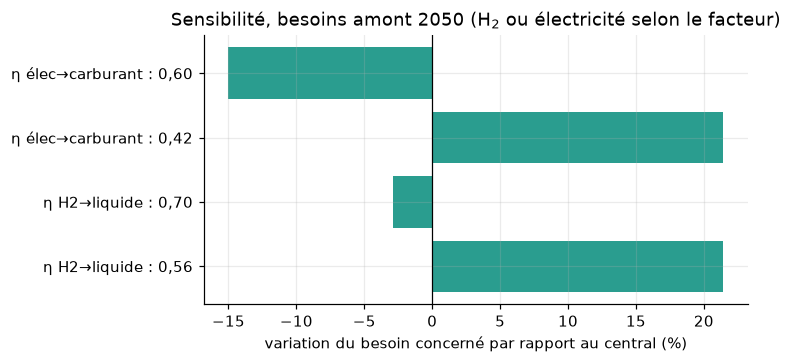

In [20]:
y = 2050
base = besoins(T.loc[y, "mandat_synth_TWh"], FACT.loc["central"])
cas = {
    "η H2→liquide : 0,56": ("eta_h2_liq", FACT.loc["peu efficace", "eta_h2_liq"]),
    "η H2→liquide : 0,70": ("eta_h2_liq", FACT.loc["efficace", "eta_h2_liq"]),
    "η élec→carburant : 0,42": ("eta_elec_fuel", 0.42),
    "η élec→carburant : 0,60": ("eta_elec_fuel", 0.60),
}
res = {}
for nom, (col, val) in cas.items():
    j = FACT.loc["central"].copy(); j[col] = val
    res[nom] = besoins(T.loc[y, "mandat_synth_TWh"], j)
S = pd.DataFrame(res).T
S["Δ H2 (%)"] = 100 * (S["H2 (TWh)"] / base["H2 (TWh)"] - 1)
S["Δ électricité (%)"] = 100 * (S["électricité (TWh)"] / base["électricité (TWh)"] - 1)
print(f"Référence 2050 (central) : H2 = {base['H2 (TWh)']:.0f} TWh, électricité = {base['électricité (TWh)']:.0f} TWh, CO2 = {base['CO2 (Mt)']:.0f} Mt")
print(S[["H2 (TWh)", "électricité (TWh)", "Δ H2 (%)", "Δ électricité (%)"]].round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
concerne = S["Δ électricité (%)"].where(S.index.str.contains("élec"), S["Δ H2 (%)"])   # le besoin que le facteur touche
ax.barh(S.index, concerne, color="#2a9d8f")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("variation du besoin concerné par rapport au central (%)")
ax.set_title("Sensibilité, besoins amont 2050 (H$_2$ ou électricité selon le facteur)")
plt.tight_layout(); plt.show()

**Lecture.** Les deux rendements jouent chacun sur **un** besoin : η H₂→liquide sur l'hydrogène, η électricité→carburant sur l'électricité. La barre de la figure donne le besoin concerné (hydrogène pour les deux premières lignes, électricité pour les deux dernières). En 2050 : passer à 0,56 augmente l'hydrogène de 21 % (0,70 le réduit de 3 %), et passer à 0,42 augmente l'électricité de 21 % (0,60 la réduit de 15 %). **L'asymétrie** vient du fait que le central est déjà proche de la borne haute pour l'hydrogène : l'incertitude est surtout vers le **haut**.

## 7. Comparaison des scénarios : NT+, HEV, LEV

HEV et LEV ne sont publiés que pour **2035 et 2040**. La demande de e-fuels est la même dans les trois scénarios, mais la demande totale de liquides ne l'est pas : la **part** de e-liquides change donc.

In [21]:
rows = []
for v in ["NT+", "HEV", "LEV"]:
    t = trajectoire(v, ETA)
    t["scénario"] = v
    rows.append(t.reset_index(names="année"))
SC = pd.concat(rows)
print(SC.pivot_table(index="scénario", columns="année",
                     values=["aviation_liquides", "liquides_tous_secteurs", "e_liquides", "part_eSAF_prorata_%"]).round(1).to_string())

         aviation_liquides                      e_liquides                      liquides_tous_secteurs                         part_eSAF_prorata_%                 
année                 2030   2035   2040   2050       2030   2035   2040   2050                   2030    2035    2040    2050                2030 2035  2040  2050
scénario                                                                                                                                                           
HEV                    NaN  589.3  600.7    NaN        NaN  185.0  317.7    NaN                    NaN  3876.9  3038.1     NaN                 NaN  4.8  10.5   NaN
LEV                    NaN  577.5  581.7    NaN        NaN  185.0  317.7    NaN                    NaN  4115.2  3414.6     NaN                 NaN  4.5   9.3   NaN
NT+                  603.9  583.4  591.1  566.4       73.4  185.0  317.7  607.0                 4840.3  3995.6  3226.2  1964.4                 1.5  4.6   9.8  30.9


In [22]:
# Pays choisi : demande d'aviation (liquides) et production nationale de e-liquides par scénario
def pays_tab(code):
    a = av[(av.country == code) & (av.carrier == "Liquids")].groupby(["variant", "year"]).twh.sum().rename("aviation_liquides")
    h = (kpi[(kpi.country == code) & (kpi.label == "H2 to E-Liquids") & (kpi.section == "Consumption")]
         .groupby(["variant", "year"]).value.sum().rename("H2_vers_eliquides"))
    return pd.concat([a, h], axis=1).fillna({"H2_vers_eliquides": 0}).reset_index()
PT = pays_tab(PAYS)
PT["eliquides_nationaux_TWh"] = PT.H2_vers_eliquides * ETA
PT["couverture_nationale_%"] = 100 * PT.eliquides_nationaux_TWh / PT.aviation_liquides
print(f"{PAYS} : aviation (liquides) et production nationale de e-liquides")
print(PT.pivot(index="variant", columns="year", values=["aviation_liquides", "couverture_nationale_%"]).round(1).to_string())

FR : aviation (liquides) et production nationale de e-liquides
        aviation_liquides                   couverture_nationale_%                 
year                 2030  2035  2040  2050                   2030 2035  2040  2050
variant                                                                            
HEV                   NaN  93.9  89.4   NaN                    NaN  7.2  12.5   NaN
LEV                   NaN  91.8  87.5   NaN                    NaN  7.4  17.9   NaN
NT+                 101.6  92.9  88.5  80.2                    1.6  7.3  16.7  59.5


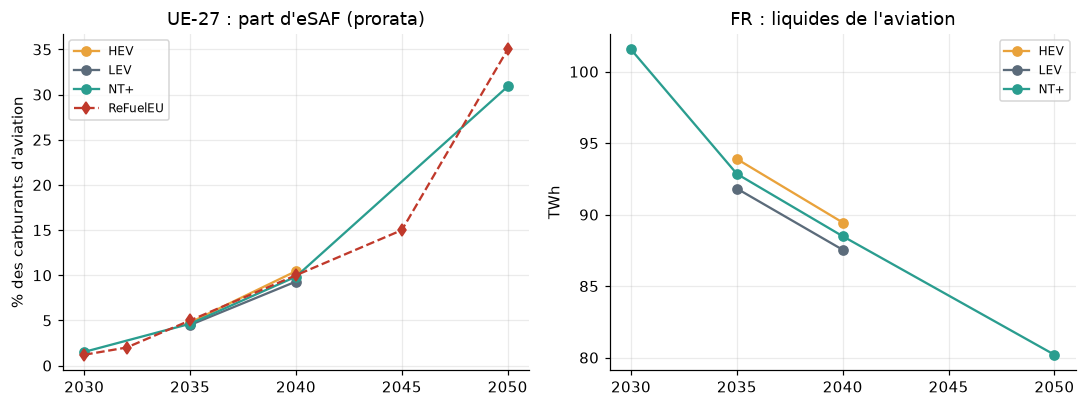

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
couleurs = {"NT+": "#2a9d8f", "HEV": "#e9a23b", "LEV": "#5b6b7a"}
for v, g in SC.groupby("scénario"):
    axes[0].plot(g["année"], g["part_eSAF_prorata_%"], "o-", color=couleurs[v], label=v)
axes[0].plot(ref.annee[ref.annee >= 2030], ref.part_synthetique_min_pct[ref.annee >= 2030], "d--", color="#c0392b", label="ReFuelEU")
axes[0].set_title("UE-27 : part d'eSAF (prorata)"); axes[0].set_ylabel("% des carburants d'aviation"); axes[0].legend(fontsize=8)
for v, g in PT.groupby("variant"):
    axes[1].plot(g["year"], g["aviation_liquides"], "o-", color=couleurs[v], label=v)
axes[1].set_title(f"{PAYS} : liquides de l'aviation"); axes[1].set_ylabel("TWh")
axes[1].legend(fontsize=8)
for a in axes: a.set_xticks([2030, 2035, 2040, 2045, 2050])
plt.tight_layout(); plt.show()

**Lecture.** Dans l'UE-27 les liquides de l'aviation varient peu entre scénarios (moins de 3 % d'écart à NT+ en 2035-2040), alors que les liquides de l'économie entière sont plus élevés dans LEV que dans HEV (colonne `liquides_tous_secteurs`) ; comme le volume de e-liquides est le même, la **part** d'eSAF au prorata est plus faible dans LEV (4,5 % et 9,3 %) que dans HEV (4,8 % et 10,5 %). Le pays choisi se lit à l'échelle nationale : si `couverture_nationale_%` vaut zéro, le pays **n'a aucune usine nationale de e-liquides** dans TYNDP et dépend des importations de l'UE-27, ce qui est le cas de la majorité des États membres (section suivante).

Pays avec une production nationale de e-liquides en 2050 (TWh) :
      aviation     H2  couverture_%
pays                               
DE       150.2  129.6          58.7
IT        70.4   73.3          70.8
FR        80.2   70.2          59.5
ES        83.0   62.6          51.3
FI         8.7   29.7         232.2
DK        11.5   18.9         111.4
BE        24.9   17.2          46.9
GR        18.3    9.4          34.8
Somme de ces pays vs UE-27 (H2 vers e-liquides) : 410.9 vs 410.9
19 pays sur 27 sans production nationale
Une couverture > 100 % (Finlande, Danemark) signifie que le pays produit plus que sa propre aviation : un exportateur de e-liquides dans la logique de TYNDP.


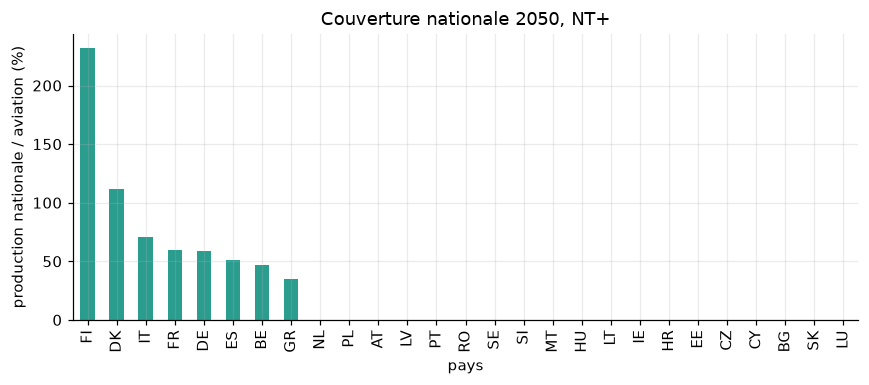

In [24]:
# Quels pays produisent des e-liquides ? Couverture nationale 2050, scénario de référence
c = []
for code_pays in UE27:
    t = pays_tab(code_pays)
    t = t[(t.variant == SCENARIO_REF) & (t.year == 2050)]
    if len(t): c.append(dict(pays=code_pays, aviation=t.aviation_liquides.iloc[0], H2=t.H2_vers_eliquides.iloc[0]))
C_ = pd.DataFrame(c).set_index("pays")
C_["couverture_%"] = 100 * C_.H2 * ETA / C_.aviation
print("Pays avec une production nationale de e-liquides en 2050 (TWh) :")
print(C_[C_.H2 > 0].sort_values("H2", ascending=False).round(1).to_string())
print("Somme de ces pays vs UE-27 (H2 vers e-liquides) :", round(C_.H2.sum(), 1), "vs", round(float(kpi_ue("H2 to E-Liquids", "Consumption")[2050]), 1))
print(len(C_[C_.H2 == 0]), "pays sur 27 sans production nationale")
print("Une couverture > 100 % (Finlande, Danemark) signifie que le pays produit plus que sa propre aviation : un exportateur de e-liquides dans la logique de TYNDP.")
fig, ax = plt.subplots(figsize=(8, 3.6))
C_["couverture_%"].sort_values(ascending=False).plot.bar(ax=ax, color="#2a9d8f")
ax.set_ylabel("production nationale / aviation (%)"); ax.set_title(f"Couverture nationale 2050, {SCENARIO_REF}")
plt.tight_layout(); plt.show()

## 8. Exercices ouverts

Chaque exercice se traite dans les cellules vides qui suivent. Il n'y a pas de bonne réponse unique : **justifiez vos hypothèses** et dites ce que les données ne permettent pas de conclure.

1. **Règle d'affectation.** Entre « au prorata » et « aviation d'abord », proposez une troisième règle (par exemple : aviation + maritime, ou selon la sous-obligation ReFuelEU) et recalculez la part d'eSAF 2050. Que change-t-elle ?
2. **Le pays à l'échelle nationale.** Pour votre `PAYS`, comparez la production nationale de e-liquides avec l'obligation proportionnelle (mandat × aviation du pays). Le pays est-il importateur net ? Quelle part de l'UE-27 importe-t-il ?
3. **Besoins amont du pays.** Calculez l'électricité qu'il faudrait pour produire sur place l'eSAF exigé pour l'aviation du pays en 2050 et comparez-la à la production d'électricité actuelle (donnée à chercher, source à citer).
4. **Rendements.** Quelle est la sensibilité de la demande d'électricité de l'UE-27 en 2050 si le rendement électricité→carburant passe de 0,51 à 0,42 ? Est-ce plausible dans le cadre de l'extrapolation TYNDP ?
5. **Scénarios.** Pourquoi la **part** d'eSAF diffère-t-elle entre NT+, HEV et LEV alors que la demande de e-fuels est identique ? Refaites le calcul en fixant la demande de liquides de NT+.
6. **Critique.** Listez trois limites de la méthode (agrégats, affectation, rendement unique). Laquelle pèse le plus sur la comparaison avec ReFuelEU ?
7. **Question ouverte.** Les imports d'e-liquides représentent plus de la moitié de l'offre dans TYNDP. Quelles conséquences pour la conformité des fournisseurs européens à la sous-obligation ?

**Exercice 1** — votre réponse (texte) :

In [25]:
# Exercice 1

**Exercice 2** — votre réponse (texte) :

In [26]:
# Exercice 2

**Exercice 3** — votre réponse (texte) :

In [27]:
# Exercice 3

**Exercice 4** — votre réponse (texte) :

In [28]:
# Exercice 4

**Exercice 5** — votre réponse (texte) :

In [29]:
# Exercice 5

**Exercice 6** — votre réponse (texte) :

In [30]:
# Exercice 6

**Exercice 7** — votre réponse (texte) :

In [31]:
# Exercice 7

---
### Sources
- TYNDP 2026 Scenarios, ENTSO-E / ENTSOG, licence CC BY 4.0 — « TYNDP 2026 Scenarios » (page de téléchargement 2026.entsos-tyndp-scenarios.eu/download/).
- Règlement (UE) 2023/2405 du Parlement européen et du Conseil du 18 octobre 2023 (ReFuelEU Aviation), annexe I, JO L du 31.10.2023 (EUR-Lex, CELEX 32023R2405).
- Concawe (2024), *E-Fuels: A techno-economic assessment of European domestic production and imports towards 2050 — Update*, Report 4/24.
- Ueckerdt, F. et al. (2021), *Potential and risks of hydrogen-based e-fuels in climate change mitigation*, Nature Climate Change 11, 384–393.